In [51]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [52]:
train = pd.read_csv('sign_mnist_train.csv')
test = pd.read_csv('sign_mnist_test.csv')

In [53]:
x_train = train.drop('label',axis=1).values
y_train = train['label'].values

In [54]:
x_test = test.drop('label',axis=1).values
y_test = test['label'].values

In [55]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [56]:
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

In [57]:
model = keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3), activation = 'relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3), activation = 'relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128,activation = 'relu'),
    layers.Dense(25,activation = 'softmax')
])
    

In [58]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [59]:
history = model.fit(
    x_train,y_train,
    epochs = 10,
    batch_size = 32,
    validation_data = (x_test,y_test)
)

Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7247 - loss: 0.9364 - val_accuracy: 0.8586 - val_loss: 0.4491
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9888 - loss: 0.0585 - val_accuracy: 0.9010 - val_loss: 0.3074
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9975 - loss: 0.0161 - val_accuracy: 0.8861 - val_loss: 0.4306
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9999 - loss: 0.0028 - val_accuracy: 0.9087 - val_loss: 0.3662
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9932 - loss: 0.0223 - val_accuracy: 0.8991 - val_loss: 0.3664
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 1.0000 - loss: 6.5524e-04 - val_accuracy: 0.9102 - val_loss: 0.3553
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 1.0000 - loss: 3.1350e-04 - val_accuracy: 0.9158 - val_loss: 0.3861
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 1.0000 - loss: 1.7926e-04 - val_

In [60]:
loss, accuracy = model.evaluate(x_test,y_test)
print('Testing loss = ',accuracy * 100)
print('Training loss = ', history.history['accuracy'][-1] * 100)

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9085 - loss: 0.4163
Testing loss =  90.85331559181213
Training loss =  99.11856055259705


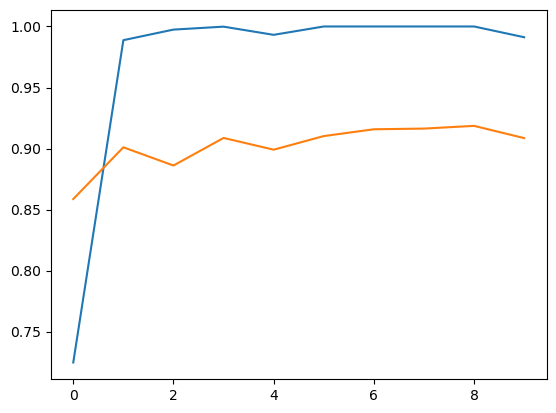

In [61]:
plt.plot(history.history['accuracy'],label = 'Training accuracy')
plt.plot(history.history['val_accuracy'],label = 'Testing accuracy')
plt.show()

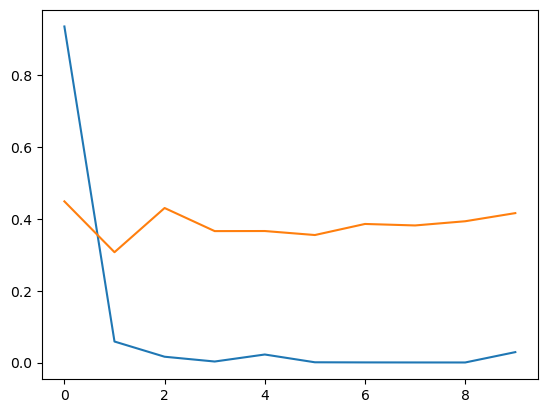

In [62]:
plt.plot(history.history['loss'],label='training loss')
plt.plot(history.history['val_loss'],label = 'testing loss')
plt.show()

In [63]:
predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


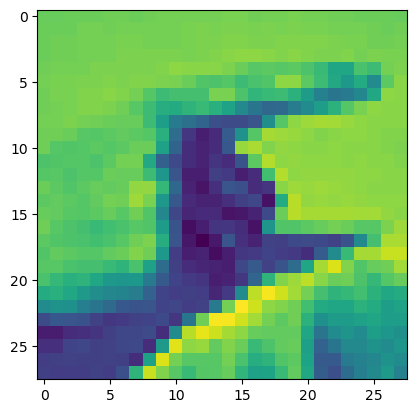

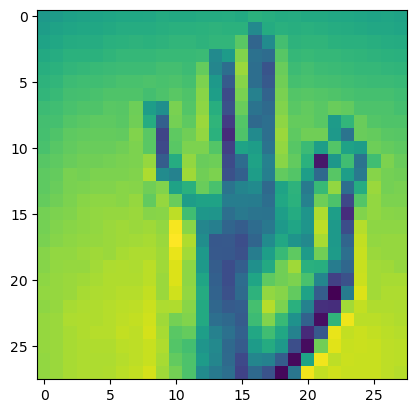

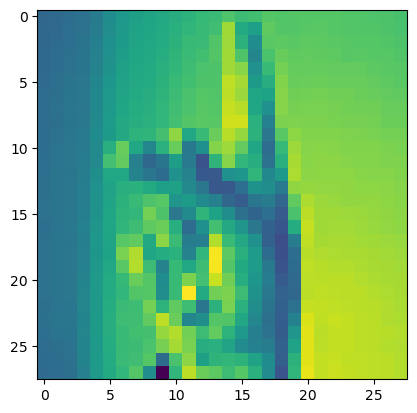

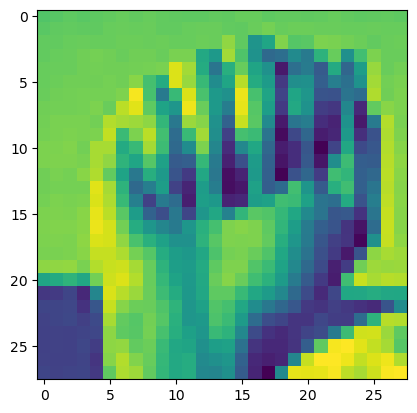

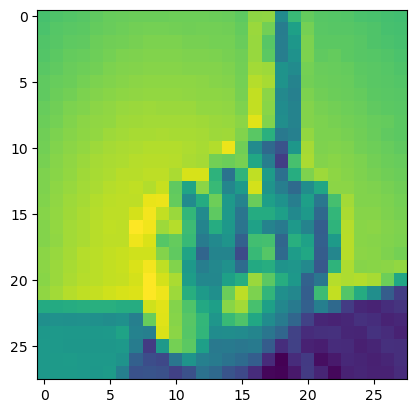

In [68]:
for i in range(5):
    plt.imshow(x_test[i].reshape(28,28,1))
    plt.show()

In [72]:
for i in range(5):
    print('Actual = ',y_test[i],
    'predicted = ',predicted_labels[i])

Actual =  6 predicted =  6
Actual =  5 predicted =  5
Actual =  10 predicted =  10
Actual =  0 predicted =  0
Actual =  3 predicted =  3


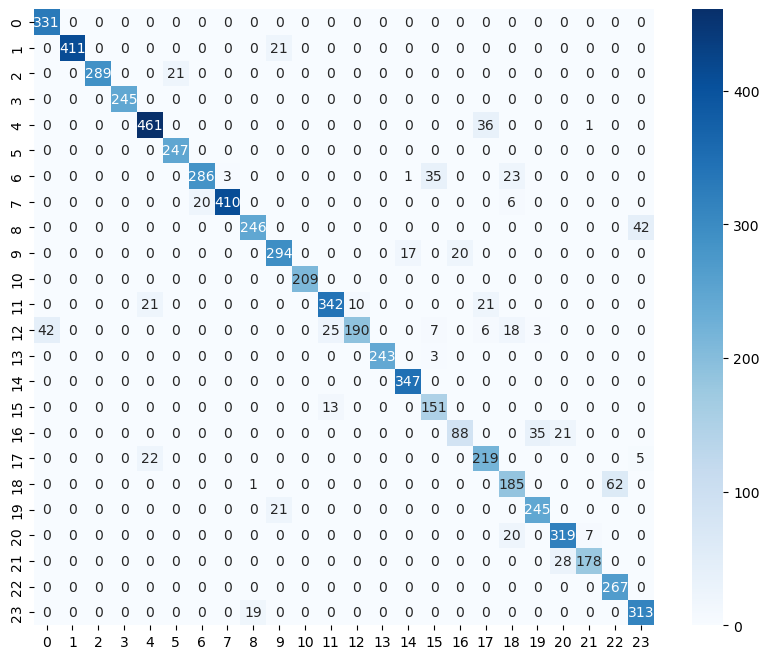

In [75]:
cm = confusion_matrix(y_test,predicted_labels)
plt.figure(figsize=(10,8))
sns.heatmap(cm,annot=True,fmt = 'd',cmap='Blues')
plt.show()